# 04 — Réglage du MLP (learning rate & régularisation)

Objectif : améliorer le MLP du notebook 03 en réglant son **learning rate** et sa **régularisation**
(`weight_decay` AdamW et dropout), puis le comparer au **benchmark** : la régression logistique one-vs-rest
(8 classifieurs binaires, 768 dimensions, C=1), retenue dans le notebook 03.

**Protocole** (identique au notebook 03)
- **Sélection** : validation croisée à 5 folds stratifiée multi-label sur **train + val**.
- **Critère** : Macro-AP, indépendante des seuils.
- **Early stopping** : dans chaque fold, il utilise le fold d'évaluation, de la même manière pour toutes les configurations.
- **Modèle final** : entraîné sur train, early stopping et seuils par tag sur val, évaluation **une seule fois** sur le test.

In [1]:
import logging
import sys
import time
from dataclasses import replace
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import TARGET_TAGS, LogRegConfig, MLPConfig, TuningConfig
from src.dataset import load_modeling_data
from src.evaluate import (
    apply_thresholds,
    bootstrap_macro_f1_diff,
    global_metrics,
    per_tag_metrics,
    tune_thresholds,
)
from src.linear import build_logreg, fit_predict_logreg
from src.mlp import fit_predict_mlp, predict_proba, train_mlp
from src.tuning import cross_val_scores, grid_search

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid", context="notebook")

BASE_MLP_CFG = MLPConfig()
BENCHMARK_CFG = LogRegConfig()
TUNING_CFG = TuningConfig()

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 10:53:01.210000 33925 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
data = load_modeling_data()
x, y = data.x, data.y
x_dev, y_dev = data.dev()
print({name: arr.shape for name, arr in x.items()}, "| dev :", x_dev.shape)

{'train': (3383, 768), 'val': (725, 768), 'test': (726, 768)} | dev : (4108, 768)


## 1. Références en validation croisée

In [3]:
reference_cv = {
    "logreg (benchmark)": cross_val_scores(
        partial(fit_predict_logreg, BENCHMARK_CFG), x_dev, y_dev, TUNING_CFG.n_splits
    ),
    "mlp (défaut, notebook 03)": cross_val_scores(
        partial(fit_predict_mlp, BASE_MLP_CFG), x_dev, y_dev, TUNING_CFG.n_splits
    ),
}
pd.DataFrame({name: {"cv_macro_ap": np.mean(s), "cv_std": np.std(s)} for name, s in reference_cv.items()}).T.round(4)

,cv_macro_ap,cv_std
logreg (benchmark),0.5904,0.0334
"mlp (défaut, notebook 03)",0.5840,0.0321


## 2. Recherche sur grille

| Hyperparamètre | Rôle | Valeurs |
|---|---|---|
| `lr` | pas d'apprentissage AdamW | 1e-4, 3e-4, 1e-3, 3e-3 |
| `weight_decay` | régularisation L2 des poids | 1e-4, 1e-2, 1e-1 |
| `dropout` | régularisation par extinction aléatoire | 0.2, 0.5 |

Les autres paramètres sont fixés : couche cachée de 256 neurones, batch de 64, patience de 15. Cela fait 24 configurations × 5 folds.

In [4]:
start = time.perf_counter()
mlp_grid = grid_search(
    dict(TUNING_CFG.mlp_grid),
    lambda params: partial(fit_predict_mlp, replace(BASE_MLP_CFG, **params)),
    x_dev,
    y_dev,
    TUNING_CFG.n_splits,
)
print(f"Grid search : {time.perf_counter() - start:.0f}s")
mlp_grid.head(10).round(4)

Grid search : 113s


,lr,weight_decay,dropout,cv_macro_ap,cv_std,seconds
0,0.0030,0.1000,0.5,0.5876,0.0282,2.1954
1,0.0003,0.1000,0.5,0.5854,0.0309,4.7452
2,0.0001,0.1000,0.5,0.5852,0.0315,12.1705
3,0.0001,0.0100,0.5,0.5852,0.0310,10.8490
4,0.0003,0.0100,0.2,0.5847,0.0305,3.8854
5,0.0003,0.1000,0.2,0.5847,0.0308,4.0790
6,0.0001,0.1000,0.2,0.5847,0.0322,8.7427
7,0.0003,0.0001,0.2,0.5847,0.0305,3.8845
8,0.0001,0.0001,0.5,0.5844,0.0318,10.7000
9,0.0003,0.0001,0.5,0.5843,0.0310,4.6233


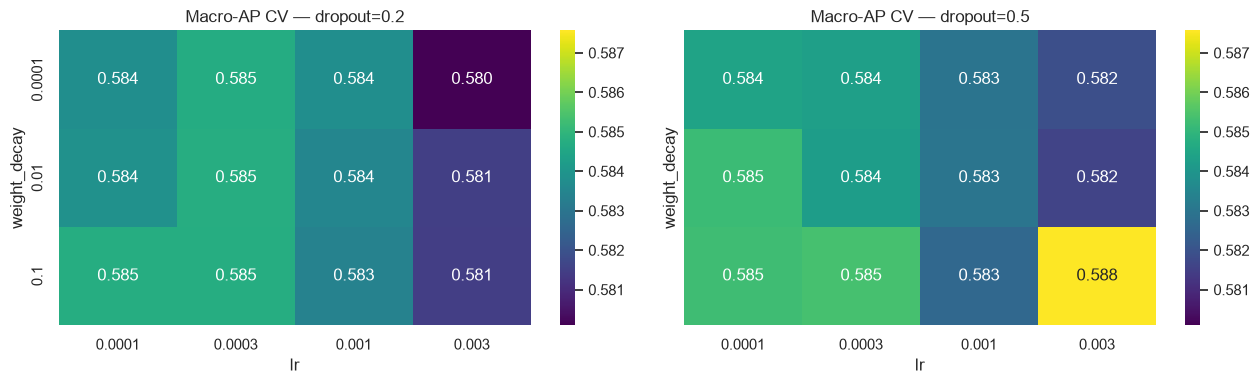

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (dropout, sub) in zip(axes, mlp_grid.groupby("dropout")):
    table = sub.pivot(index="weight_decay", columns="lr", values="cv_macro_ap")
    sns.heatmap(table, annot=True, fmt=".3f", cmap="viridis", vmin=mlp_grid["cv_macro_ap"].min(),
                vmax=mlp_grid["cv_macro_ap"].max(), ax=ax)
    ax.set(title=f"Macro-AP CV — dropout={dropout}")
plt.tight_layout()
plt.show()

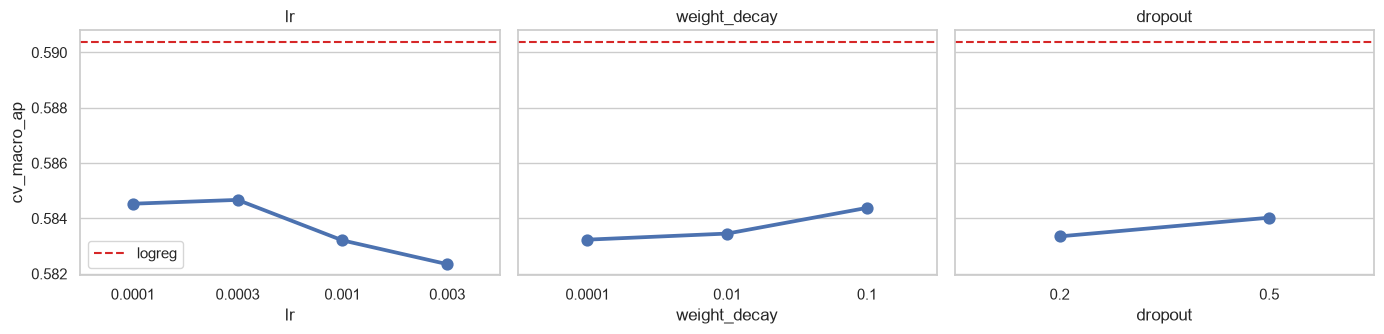

In [6]:
# Effet marginal de chaque hyperparamètre (moyenne sur les autres)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, param in zip(axes, ["lr", "weight_decay", "dropout"]):
    sns.pointplot(data=mlp_grid, x=param, y="cv_macro_ap", ax=ax, errorbar=None)
    ax.axhline(np.mean(reference_cv["logreg (benchmark)"]), color="tab:red", linestyle="--", label="logreg")
    ax.set(title=param)
axes[0].legend()
plt.tight_layout()
plt.show()

### Deuxième passe : prolonger la grille au-delà de son bord

L'optimum de la première grille est dans un **coin** : `weight_decay=0.1` et `dropout=0.5` sont les valeurs maximales
testées. On prolonge donc vers une régularisation plus forte, pour vérifier qu'on n'a pas manqué un meilleur optimum.

In [7]:
refine_grid = grid_search(
    dict(TUNING_CFG.mlp_refine_grid),
    lambda params: partial(fit_predict_mlp, replace(BASE_MLP_CFG, **params)),
    x_dev,
    y_dev,
    TUNING_CFG.n_splits,
)
all_results = (
    pd.concat([mlp_grid.assign(passe=1), refine_grid.assign(passe=2)])
    .drop_duplicates(["lr", "weight_decay", "dropout"])
    .sort_values("cv_macro_ap", ascending=False, ignore_index=True)
)
print(f"Macro-AP CV sur les {len(all_results)} configurations : "
      f"min {all_results['cv_macro_ap'].min():.4f}, max {all_results['cv_macro_ap'].max():.4f}")
all_results.head(8).round(4)

Macro-AP CV sur les 34 configurations : min 0.5801, max 0.5883


,lr,weight_decay,dropout,cv_macro_ap,cv_std,seconds,passe
0,0.0030,0.30,0.5,0.5883,0.0305,2.2026,2
1,0.0030,0.10,0.5,0.5876,0.0282,2.1954,1
2,0.0030,1.00,0.5,0.5867,0.0342,3.9269,2
3,0.0030,0.30,0.7,0.5863,0.0346,2.5577,2
4,0.0003,0.10,0.5,0.5854,0.0309,4.7452,1
5,0.0001,0.10,0.5,0.5852,0.0315,12.1705,1
6,0.0001,0.01,0.5,0.5852,0.0310,10.8490,1
7,0.0010,0.30,0.5,0.5848,0.0326,3.0149,2


In [8]:
best = all_results.iloc[0]
tuned_cfg = replace(BASE_MLP_CFG, lr=float(best["lr"]), weight_decay=float(best["weight_decay"]), dropout=float(best["dropout"]))
print("MLP retenu :", tuned_cfg)
print(f"Macro-AP CV : {best['cv_macro_ap']:.4f} ± {best['cv_std']:.4f} "
      f"(logreg : {np.mean(reference_cv['logreg (benchmark)']):.4f})")

MLP retenu : MLPConfig(hidden_dim=256, dropout=0.5, lr=0.003, weight_decay=0.3, batch_size=64, max_epochs=200, patience=15)
Macro-AP CV : 0.5883 ± 0.0305 (logreg : 0.5904)


## 3. Entraînement final et courbes d'apprentissage

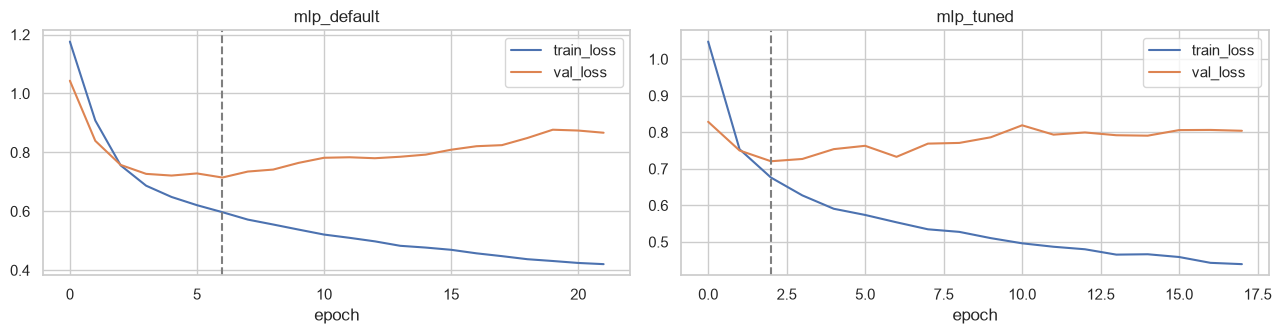

In [9]:
mlps, histories = {}, {}
for name, cfg in {"mlp_default": BASE_MLP_CFG, "mlp_tuned": tuned_cfg}.items():
    mlps[name], histories[name] = train_mlp(x["train"], y["train"], x["val"], y["val"], cfg)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, (name, history) in zip(axes, histories.items()):
    history.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax, title=name)
    ax.axvline(history["val_loss"].idxmin(), color="gray", linestyle="--")
plt.tight_layout()
plt.show()

In [10]:
benchmark = build_logreg(BENCHMARK_CFG).fit(x["train"], y["train"])
probas = {
    "logreg": (benchmark.predict_proba(x["val"]), benchmark.predict_proba(x["test"])),
    **{name: (predict_proba(m, x["val"]), predict_proba(m, x["test"])) for name, m in mlps.items()},
}
thresholds, predictions = {}, {}
for name, (proba_val, proba_test) in probas.items():
    thresholds[name] = tune_thresholds(y["val"], proba_val)
    predictions[name] = apply_thresholds(proba_test, thresholds[name])
pd.DataFrame(thresholds, index=TARGET_TAGS).T.round(2)

,math,graphs,strings,number theory,trees,geometry,games,probabilities
logreg,0.50,0.72,0.82,0.77,0.70,0.79,0.85,0.72
mlp_default,0.46,0.71,0.71,0.64,0.68,0.80,0.94,0.87
mlp_tuned,0.48,0.77,0.62,0.81,0.67,0.75,0.91,0.93


## 4. Comparaison sur le test

In [11]:
pd.DataFrame({name: global_metrics(y["test"], pred) for name, pred in predictions.items()}).T.round(3)

,micro_f1,macro_f1,hamming_loss,jaccard_samples
logreg,0.554,0.612,0.083,0.532
mlp_default,0.532,0.575,0.105,0.437
mlp_tuned,0.515,0.543,0.097,0.456


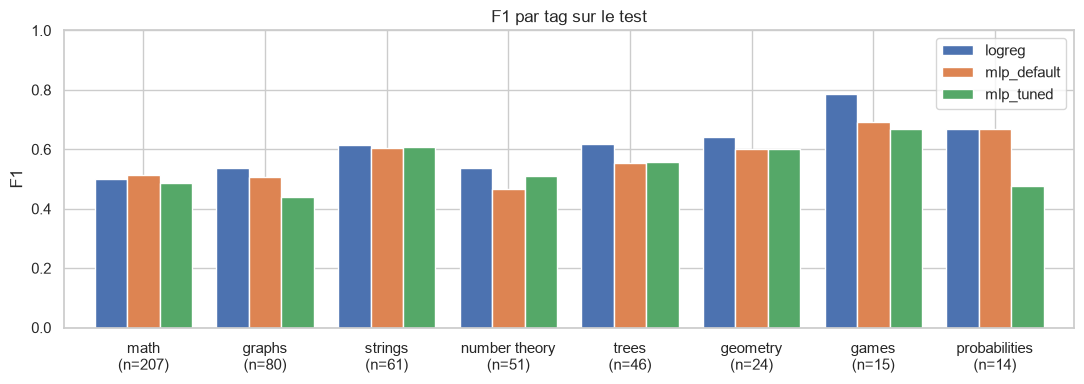

,math,graphs,strings,number theory,trees,geometry,games,probabilities
logreg,0.50,0.54,0.61,0.54,0.62,0.64,0.79,0.67
mlp_default,0.51,0.51,0.61,0.47,0.56,0.60,0.69,0.67
mlp_tuned,0.49,0.44,0.61,0.51,0.56,0.60,0.67,0.48


In [12]:
f1_by_tag = pd.DataFrame(
    {name: per_tag_metrics(y["test"], pred, TARGET_TAGS)["f1"] for name, pred in predictions.items()}
)
support = y["test"].sum(axis=0)

fig, ax = plt.subplots(figsize=(11, 4))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.8)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TARGET_TAGS, support)])
plt.tight_layout()
plt.show()
f1_by_tag.round(2).T

In [13]:
pd.DataFrame(
    {
        f"{a} - {b}": bootstrap_macro_f1_diff(y["test"], predictions[a], predictions[b], TUNING_CFG.n_bootstrap)
        for a, b in [("mlp_tuned", "logreg"), ("mlp_tuned", "mlp_default")]
    }
).T.round(3)

,diff_mean,ci_low,ci_high,p_a_better
mlp_tuned - logreg,-0.070,-0.118,-0.028,0.001
mlp_tuned - mlp_default,-0.033,-0.067,-0.000,0.025


### Stabilité vis-à-vis de la graine

Un MLP dépend de son initialisation. On ré-entraîne la configuration retenue avec 5 graines pour mesurer la dispersion
du Macro-F1 sur le test. La régression logistique, convexe, est déterministe.

In [14]:
seed_scores = []
for seed in range(5):
    model, _ = train_mlp(x["train"], y["train"], x["val"], y["val"], tuned_cfg, seed=seed)
    th = tune_thresholds(y["val"], predict_proba(model, x["val"]))
    pred = apply_thresholds(predict_proba(model, x["test"]), th)
    seed_scores.append(global_metrics(y["test"], pred)["macro_f1"])

logreg_f1 = global_metrics(y["test"], predictions["logreg"])["macro_f1"]
print(f"MLP réglé, Macro-F1 test sur 5 graines : {np.mean(seed_scores):.3f} ± {np.std(seed_scores):.3f} "
      f"(min {min(seed_scores):.3f}, max {max(seed_scores):.3f}) | logreg : {logreg_f1:.3f}")

MLP réglé, Macro-F1 test sur 5 graines : 0.562 ± 0.011 (min 0.551, max 0.582) | logreg : 0.612


## 5. Constats

**Validation croisée (critère de sélection)**

| Modèle | Macro-AP CV |
|---|---|
| Régression logistique (benchmark) | **0.590** ± 0.033 |
| MLP par défaut (lr 1e-3, wd 1e-4, dropout 0.3) | 0.584 ± 0.032 |
| MLP réglé (lr 3e-3, wd 0.3, dropout 0.5) | 0.588 ± 0.031 |

**Test (726 exemples)**

| Modèle | Micro-F1 | Macro-F1 | Hamming | Jaccard |
|---|---|---|---|---|
| Régression logistique | **0.554** | **0.612** | **0.083** | **0.532** |
| MLP par défaut | 0.532 | 0.575 | 0.105 | 0.437 |
| MLP réglé | 0.515 | 0.543 | 0.097 | 0.456 |

- **Le réglage ne débloque pas le MLP.** Sur 34 configurations (2 passes), la Macro-AP CV ne varie que de 0.580 à 0.588.
  Cet écart est 4 fois plus petit que l'écart-type entre folds (~0.03) : learning rate et régularisation **ne sont pas le facteur
  limitant**.
- **Les meilleures configurations sont les plus régularisées** (weight decay 0.1 à 1.0, dropout 0.5). Plus on contraint le
  MLP, plus il se rapproche d'un modèle linéaire… sans jamais dépasser la régression logistique. Le signal présent dans les
  embeddings figés est essentiellement **linéairement exploitable**, et la couche cachée n'apporte que de la variance.
- **La régression logistique reste significativement meilleure sur le test** : écart de Macro-F1 de -0.07 pour le MLP réglé,
  IC 95 % bootstrap [-0.12, -0.03].
- **Le MLP est instable** : selon la graine, son Macro-F1 test varie de 0.551 à 0.582 (0.562 ± 0.011). La régression logistique,
  convexe, est déterministe.
- **Les seuils réglés sur la validation amplifient cette instabilité.** Pour `probabilities`, le MLP réglé obtient le
  seuil 0.93 sur la validation (14 positifs seulement) : son F1 test chute à 0.48, contre 0.67 pour la régression logistique.
  Avec si peu de positifs, le réglage des seuils sur-apprend la validation.

**Décision et pistes**
1. **Modèle retenu sur les embeddings : la régression logistique** (768 dimensions, C=1). Elle est meilleure, déterministe,
   rapide et facile à expliquer.
2. Le gain ne viendra pas d'un classifieur plus complexe sur ces mêmes embeddings, mais de **nouvelles informations** :
   features du **code source**, métadonnées (`difficulty`), ou fine-tuning de l'encodeur sur la tâche.
3. Fiabiliser les seuils des tags rares : les régler sur les prédictions out-of-fold de la validation croisée (≈ 4 100
   exemples) plutôt que sur la seule validation (725).